# Cross-model robustness of poet-level textual unpredictability

This notebook reuses the existing PDF layout reconstruction and stanza-preserving chunking pipeline. It scores the same chunks with multiple open-weight causal language models, bins chunk-level BPC values into frequency histograms, estimates source-level moments from those frequencies, and compares poet rankings across models.

**Interpretation:** BPC is measured in bits per character to reduce direct dependence on tokenizer vocabulary size. Absolute scores can still differ across models; rank correlations test whether the relative ordering of poets is robust.

In [3]:
%pip install -q pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 77.4 MB/s eta 0:00:00:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path

# =========================
# CONFIGURATION
# =========================

DATASET_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working/poet_model_robustness")

# Minimum words per chunk.
MIN_WORDS = 200

# Models are configurable; all are public Hugging Face checkpoints.
MODEL_NAMES = {
    "gpt2": "gpt2",
    "pythia_410m": "EleutherAI/pythia-410m",
    "qwen2_5_0_5b": "Qwen/Qwen2.5-0.5B",
    "tinyllama_1_1b": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
}

MAX_BINS = 30
MIN_BINS = 8

# Automatically use Kaggle GPU if available.
# The explicit import is repeated here so this cell is standalone.
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Sliding-window stride for sequences longer than the model context.
STRIDE = 512

# Controls.
COMPUTE_WORD_SHUFFLE_CONTROL = True
SHUFFLE_SEEDS = [17]

COMPUTE_LZ_CONTROL = True

LOWERCASE_FOR_LM = False
KEEP_APOSTROPHES = True
KEEP_INTERNAL_HYPHENS = True

# PDF layout heuristics.
HEADER_FRACTION = 0.085
FOOTER_FRACTION = 0.075
STANZA_GAP_MULTIPLIER = 1.55

TITLE_UPPERCASE_RATIO = 0.82
TITLE_MAX_CHARS = 120
TITLE_MAX_WORDS = 15
TITLE_FONT_FACTOR = 1.18

NON_POEM_PATTERNS = [
    r"^source note$",
    r"^poems recovered",
    r"^working corpus",
    r"^acknowledg(?:e)?ments?$",
    r"^about the author$",
    r"^copyright",
    r"^contents$",
    r"^table of contents$",
    r"^introduction$",
    r"^foreword$",
    r"^notes? on the text$",
    r"^books by ",
    r"^also by ",
    r"^publisher",
    r"^penguin books",
    r"^gallery books",
    r"^faber",
]

HISTOGRAM_METHOD = "fd"
CONTACT_SHEET_COLUMNS = 4
CONTACT_SHEET_DPI = 180

TARGET_POETS = [
    "Tracy K. Smith",
    "Marie Howe",
    "Margaret Atwood",
    "Ocean Vuong",
    "Rita Dove",
    "Kaveh Akbar",
    "Don Paterson",
    "A. E. Stallings",
    "Maria Hummel",
    "Patricia Lockwood",
    "Megan Fernandes",
    "Amanda Gorman",
    "Eleanor Wilner",
    "Sasha Debevec-McKenney",
    "Aria Aber",
    "Evie Shockley",
    "John Lee Clark",
    "Kimiko Hahn",
    "Vona Groarke",
    "Danez Smith",
    "Max Ritvo",
    "Anselm Berrigan",
    "Meena Alexander",
    "Andrea Cohen",
    "Nick Laird",
    "Hala Alyan",
    "Terrance Hayes",
    "Jennifer Chang",
    "Frieda Hughes",
]

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Extract ZIP datasets from Kaggle input folders when PDFs are not already exposed.
import zipfile
EXTRACT_ROOT = Path("/kaggle/working/poet_dataset_extracted")
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)
zip_files = sorted(DATASET_ROOT.rglob("*.zip"))
for zip_path in zip_files:
    destination = EXTRACT_ROOT / zip_path.stem
    marker = destination / ".extracted"
    if not marker.exists():
        destination.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(destination)
        marker.write_text("ok")
if zip_files:
    DATASET_ROOT = EXTRACT_ROOT

print("Dataset root:", DATASET_ROOT)
print("Output root:", OUTPUT_ROOT)
print("Models:", MODEL_NAMES)
print("Device:", DEVICE)
print("Minimum words:", MIN_WORDS)

Dataset root: /kaggle/input
Output root: /kaggle/working/poet_model_robustness
Models: {'gpt2': 'gpt2', 'pythia_410m': 'EleutherAI/pythia-410m', 'qwen2_5_0_5b': 'Qwen/Qwen2.5-0.5B', 'tinyllama_1_1b': 'TinyLlama/TinyLlama-1.1B-Chat-v1.0'}
Device: cuda
Minimum words: 200


In [5]:
import os
import re
import math
import json
import random
import traceback
from collections import Counter

import fitz
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, AutoModelForCausalLM

print("PyMuPDF loaded.")
print("Transformers loaded.")

PyMuPDF loaded.
Transformers loaded.


## 1. Discover poet PDFs

In [6]:
def normalize_name(s):
    s = s.lower().replace("_", " ").replace("-", " ")
    s = re.sub(r"[^a-z0-9 ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

normalized_poets = {
    normalize_name(p): p
    for p in TARGET_POETS
}

def identify_poet(path):
    stem = normalize_name(path.stem)
    matches = [
        poet
        for norm, poet in normalized_poets.items()
        if norm in stem
    ]
    return matches[0] if len(matches) == 1 else None

pdf_files = sorted(DATASET_ROOT.rglob("*.pdf"))

discovery_rows = []
poet_to_paths = {}

for path in pdf_files:
    poet = identify_poet(path)

    discovery_rows.append({
        "file": str(path),
        "poet": poet,
        "recognized": poet is not None,
    })

    if poet is not None:
        poet_to_paths.setdefault(poet, []).append(path)

discovery_df = pd.DataFrame(discovery_rows)

print("PDFs discovered:", len(pdf_files))
print(
    "Recognized target-poet PDFs:",
    int(discovery_df["recognized"].sum())
)

for poet in TARGET_POETS:
    paths = poet_to_paths.get(poet, [])
    print(f"{poet:30s} -> {len(paths)} file(s)")
    for p in paths:
        print("   ", p)

discovery_df.to_csv(
    OUTPUT_ROOT / "discovery_report.csv",
    index=False,
    encoding="utf-8-sig",
)

PDFs discovered: 32
Recognized target-poet PDFs: 28
Tracy K. Smith                 -> 1 file(s)
    /kaggle/input/datasets/srabongitikar/poetries/andrea_cohen_32_poets_delivery/02_tracy_k_smith.pdf
Marie Howe                     -> 1 file(s)
    /kaggle/input/datasets/srabongitikar/poetries/andrea_cohen_32_poets_delivery/03_marie_howe.pdf
Margaret Atwood                -> 1 file(s)
    /kaggle/input/datasets/srabongitikar/poetries/andrea_cohen_32_poets_delivery/04_margaret_atwood.pdf
Ocean Vuong                    -> 1 file(s)
    /kaggle/input/datasets/srabongitikar/poetries/andrea_cohen_32_poets_delivery/05_ocean_vuong.pdf
Rita Dove                      -> 1 file(s)
    /kaggle/input/datasets/srabongitikar/poetries/andrea_cohen_32_poets_delivery/06_rita_dove.pdf
Kaveh Akbar                    -> 1 file(s)
    /kaggle/input/datasets/srabongitikar/poetries/andrea_cohen_32_poets_delivery/07_kaveh_akbar.pdf
Don Paterson                   -> 1 file(s)
    /kaggle/input/datasets/srabongiti

## 2. Reconstruct poems and stanzas from PDF layout

The algorithm uses PDF coordinates rather than plain extracted text. It removes common page furniture, detects likely poem titles, carries poems across page boundaries, and uses vertical gaps between lines to infer stanza boundaries.

A page break alone is never considered a stanza break.

In [7]:
compiled_non_poem = [
    re.compile(pattern, re.I)
    for pattern in NON_POEM_PATTERNS
]

def normalize_spaces(text):
    return re.sub(r"[ \t]+", " ", text.strip())

def is_roman_label(text):
    return bool(
        re.fullmatch(r"[IVXLCDM]+", text.strip(), flags=re.I)
    )

def is_non_poem_line(text):
    t = normalize_spaces(text)

    if not t:
        return True

    if is_roman_label(t):
        return True

    if re.fullmatch(r"\d{1,4}", t):
        return True

    return any(rx.search(t) for rx in compiled_non_poem)

def uppercase_ratio(text):
    letters = [c for c in text if c.isalpha()]
    if not letters:
        return 0.0
    return sum(c.isupper() for c in letters) / len(letters)

def count_words(text):
    return len(re.findall(
        r"(?u)\b[\wÀ-ÖØ-öø-ÿ]+(?:['’\-][\wÀ-ÖØ-öø-ÿ]+)*\b",
        text
    ))

def extract_page_lines(page, page_number):
    data = page.get_text("dict")
    lines = []

    for block in data.get("blocks", []):
        if block.get("type") != 0:
            continue

        for line in block.get("lines", []):
            spans = [
                sp
                for sp in line.get("spans", [])
                if sp.get("text", "").strip()
            ]

            if not spans:
                continue

            spans.sort(key=lambda sp: sp["bbox"][0])

            text = "".join(
                sp["text"]
                for sp in spans
            ).strip()

            if not text:
                continue

            x0 = min(sp["bbox"][0] for sp in spans)
            y0 = min(sp["bbox"][1] for sp in spans)
            x1 = max(sp["bbox"][2] for sp in spans)
            y1 = max(sp["bbox"][3] for sp in spans)

            font_size = float(np.median([
                float(sp.get("size", 10.0))
                for sp in spans
            ]))

            lines.append({
                "page": page_number,
                "text": text,
                "x0": x0,
                "y0": y0,
                "x1": x1,
                "y1": y1,
                "font_size": font_size,
                "page_height": page.rect.height,
                "page_width": page.rect.width,
            })

    lines.sort(
        key=lambda x: (x["y0"], x["x0"])
    )

    return lines

def looks_like_title(
    text,
    font_size,
    typical_body_font,
):
    t = normalize_spaces(text)

    if not t or is_non_poem_line(t):
        return False

    if len(t) > TITLE_MAX_CHARS:
        return False

    if count_words(t) > TITLE_MAX_WORDS:
        return False

    if sum(c.isalpha() for c in t) < 2:
        return False

    if uppercase_ratio(t) >= TITLE_UPPERCASE_RATIO:
        return True

    if (
        typical_body_font
        and font_size
        >= TITLE_FONT_FACTOR * typical_body_font
    ):
        return True

    return False

def build_poems(pdf_path):
    doc = fitz.open(str(pdf_path))

    all_pages = []
    body_sizes = []

    for page_number, page in enumerate(doc, start=1):
        lines = extract_page_lines(
            page,
            page_number,
        )

        kept = []

        for line in lines:
            relative_y = (
                line["y0"]
                / max(line["page_height"], 1)
            )

            if relative_y < HEADER_FRACTION:
                continue

            if relative_y > 1.0 - FOOTER_FRACTION:
                continue

            if is_non_poem_line(line["text"]):
                continue

            kept.append(line)

            if (
                count_words(line["text"]) > 0
                and uppercase_ratio(line["text"]) < 0.95
            ):
                body_sizes.append(line["font_size"])

        all_pages.append(kept)

    doc.close()

    typical_body_font = (
        float(np.median(body_sizes))
        if body_sizes
        else 10.0
    )

    events = []

    for page_lines in all_pages:
        gaps = [
            b["y0"] - a["y1"]
            for a, b
            in zip(page_lines, page_lines[1:])
            if b["y0"] >= a["y1"]
        ]

        base_gap = (
            float(np.median(gaps))
            if gaps
            else 4.0
        )

        for line in page_lines:
            events.append({
                "kind": (
                    "title"
                    if looks_like_title(
                        line["text"],
                        line["font_size"],
                        typical_body_font,
                    )
                    else "body"
                ),
                "line": line,
                "base_gap": base_gap,
            })

    poems = []
    current = None

    def finalize():
        nonlocal current

        if current is None:
            return

        if current["current_stanza"]:
            current["stanzas"].append(
                current["current_stanza"]
            )
            current["current_stanza"] = []

        if current["stanzas"]:
            poems.append({
                "title": current["title"],
                "start_page": current["start_page"],
                "end_page": current["end_page"],
                "stanzas": current["stanzas"],
            })

        current = None

    for event in events:
        line = event["line"]

        if event["kind"] == "title":
            finalize()

            current = {
                "title": normalize_spaces(
                    line["text"]
                ),
                "start_page": line["page"],
                "end_page": line["page"],
                "stanzas": [],
                "current_stanza": [],
                "base_gap": event["base_gap"],
                "previous_line": None,
            }

            continue

        if current is None:
            continue

        stanza_break = False
        previous = current["previous_line"]

        if (
            previous is not None
            and previous["page"] == line["page"]
        ):
            gap = line["y0"] - previous["y1"]

            if gap > (
                current["base_gap"]
                * STANZA_GAP_MULTIPLIER
            ):
                stanza_break = True

        if stanza_break and current["current_stanza"]:
            current["stanzas"].append(
                current["current_stanza"]
            )
            current["current_stanza"] = []

        current["current_stanza"].append(line)
        current["end_page"] = line["page"]
        current["previous_line"] = line

    finalize()

    return poems

## 2. Build the same stanza-preserving chunks

In [10]:
def stanza_text(stanza):
    return "\n".join(
        line["text"].rstrip()
        for line in stanza
    )

def create_chunks(poems, min_words):
    chunks = []

    for poem_index, poem in enumerate(
        poems,
        start=1,
    ):
        stanza_rows = []

        for stanza_index, stanza in enumerate(
            poem["stanzas"],
            start=1,
        ):
            text = stanza_text(stanza)

            stanza_rows.append({
                "stanza_index": stanza_index,
                "text": text,
                "word_count": count_words(text),
                "page_start": stanza[0]["page"],
                "page_end": stanza[-1]["page"],
            })

        if not stanza_rows:
            continue

        poem_word_count = sum(
            row["word_count"]
            for row in stanza_rows
        )

        # Entire short poem = one chunk.
        if poem_word_count < min_words:
            chunks.append({
                "poem_index": poem_index,
                "chunk_within_poem": 1,
                "poem_title": poem["title"],
                "poem_start_page": poem["start_page"],
                "poem_end_page": poem["end_page"],
                "stanza_start": 1,
                "stanza_end": len(stanza_rows),
                "stanza_count": len(stanza_rows),
                "word_count": poem_word_count,
                "text": "\n\n".join(
                    row["text"]
                    for row in stanza_rows
                ),
            })
            continue

        current = []
        current_words = 0
        poem_chunks = []

        for stanza in stanza_rows:
            current.append(stanza)
            current_words += stanza["word_count"]

            if current_words >= min_words:
                poem_chunks.append({
                    "poem_index": poem_index,
                    "chunk_within_poem": (
                        len(poem_chunks) + 1
                    ),
                    "poem_title": poem["title"],
                    "poem_start_page": poem["start_page"],
                    "poem_end_page": poem["end_page"],
                    "stanza_start": (
                        current[0]["stanza_index"]
                    ),
                    "stanza_end": (
                        current[-1]["stanza_index"]
                    ),
                    "stanza_count": len(current),
                    "word_count": current_words,
                    "text": "\n\n".join(
                        row["text"]
                        for row in current
                    ),
                })

                current = []
                current_words = 0

        # Do not create an undersized final chunk for a long poem.
        if current:
            remainder_text = "\n\n".join(
                row["text"]
                for row in current
            )

            if (
                poem_chunks
                and current_words < min_words
            ):
                previous = poem_chunks[-1]

                previous["stanza_end"] = (
                    current[-1]["stanza_index"]
                )
                previous["stanza_count"] += len(current)
                previous["word_count"] += current_words
                previous["text"] += (
                    "\n\n" + remainder_text
                )
            else:
                poem_chunks.append({
                    "poem_index": poem_index,
                    "chunk_within_poem": (
                        len(poem_chunks) + 1
                    ),
                    "poem_title": poem["title"],
                    "poem_start_page": poem["start_page"],
                    "poem_end_page": poem["end_page"],
                    "stanza_start": (
                        current[0]["stanza_index"]
                    ),
                    "stanza_end": (
                        current[-1]["stanza_index"]
                    ),
                    "stanza_count": len(current),
                    "word_count": current_words,
                    "text": remainder_text,
                })

        chunks.extend(poem_chunks)

    for chunk_id, chunk in enumerate(
        chunks,
        start=1,
    ):
        chunk["chunk_id"] = chunk_id

    return chunks

## 3. Score chunks with each model

The scorer computes negative log-likelihood over the full chunk, using overlapping windows when a chunk exceeds the model context. It reports BPC as total bits divided by the number of characters in the same case-normalized text. Each model is loaded and released in turn to fit typical Kaggle GPU memory.

In [11]:
import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from scipy.stats import skew, kurtosis, spearmanr, kendalltau

def model_context_length(tokenizer, model):
    candidates = [
        getattr(tokenizer, "model_max_length", None),
        getattr(model.config, "n_positions", None),
        getattr(model.config, "max_position_embeddings", None),
        getattr(model.config, "max_sequence_length", None),
    ]
    candidates = [x for x in candidates if isinstance(x, int) and 1 < x < 100000]
    return min(candidates) if candidates else 1024

def score_chunk_bpc(text, tokenizer, model, context_length, stride=512):
    text_for_model = text.lower() if LOWERCASE_FOR_LM else text
    char_count = len(text_for_model)
    encoded = tokenizer(text_for_model, return_tensors="pt", add_special_tokens=False)
    input_ids = encoded["input_ids"].to(DEVICE)
    seq_len = input_ids.size(1)
    if seq_len < 2 or char_count == 0:
        return {"bpc": np.nan, "bits_per_token": np.nan, "scored_tokens": 0, "character_count": char_count}

    stride = min(stride, max(1, context_length - 1))
    total_nll = 0.0
    scored_tokens = 0
    previous_end = 0

    with torch.inference_mode():
        for end in range(min(stride, seq_len), seq_len + stride, stride):
            end = min(end, seq_len)
            begin = max(0, end - context_length)
            input_slice = input_ids[:, begin:end]
            target_ids = input_slice.clone()
            newly_scored = end - previous_end
            target_ids[:, :-newly_scored] = -100

            outputs = model(input_slice)
            logits = outputs.logits[:, :-1, :].contiguous()
            labels = target_ids[:, 1:].contiguous()
            loss_sum = torch.nn.functional.cross_entropy(
                logits.view(-1, logits.size(-1)),
                labels.view(-1),
                ignore_index=-100,
                reduction="sum",
            )
            total_nll += float(loss_sum.item())
            scored_tokens += int((labels != -100).sum().item())
            previous_end = end
            if end >= seq_len:
                break

    total_bits = total_nll / np.log(2)
    return {
        "bpc": total_bits / char_count,
        "bits_per_token": total_bits / max(scored_tokens, 1),
        "scored_tokens": scored_tokens,
        "character_count": char_count,
    }

# Reconstruct and chunk each poet once; the exact same chunk texts are scored by all models.
poet_chunks = {}
discovery_status = []
for poet in TARGET_POETS:
    paths = poet_to_paths.get(poet, [])
    if not paths:
        discovery_status.append({"poet": poet, "status": "NO_PDF_FOUND", "pdf": ""})
        continue
    pdf_path = paths[0]
    try:
        poems = build_poems(pdf_path)
        chunks = create_chunks(poems, MIN_WORDS)
        if not chunks:
            raise RuntimeError("No chunks created")
        poet_chunks[poet] = {
            "pdf": str(pdf_path),
            "poems_detected": len(poems),
            "chunks": chunks,
        }
        discovery_status.append({"poet": poet, "status": "READY", "pdf": str(pdf_path)})
        print(f"{poet}: {len(poems)} poems, {len(chunks)} chunks")
        if len(paths) > 1:
            print(f"  Note: {len(paths)} PDFs matched; using {paths[0].name}")
    except Exception as exc:
        discovery_status.append({"poet": poet, "status": f"ERROR: {type(exc).__name__}: {exc}", "pdf": str(pdf_path)})
        print(f"[SKIP] {poet}: {exc}")

pd.DataFrame(discovery_status).to_csv(OUTPUT_ROOT / "poet_discovery_status.csv", index=False)
print("Poets ready:", len(poet_chunks))

Tracy K. Smith: 126 poems, 146 chunks
Marie Howe: 32 poems, 34 chunks
Margaret Atwood: 17 poems, 217 chunks
Ocean Vuong: 26 poems, 33 chunks
Rita Dove: 110 poems, 115 chunks
Kaveh Akbar: 59 poems, 61 chunks
Don Paterson: 81 poems, 107 chunks
Maria Hummel: 32 poems, 33 chunks
Patricia Lockwood: 24 poems, 41 chunks
Megan Fernandes: 58 poems, 58 chunks
Amanda Gorman: 129 poems, 146 chunks
Eleanor Wilner: 110 poems, 132 chunks
Sasha Debevec-McKenney: 39 poems, 54 chunks
Aria Aber: 90 poems, 103 chunks
Evie Shockley: 27 poems, 59 chunks
John Lee Clark: 43 poems, 46 chunks
Kimiko Hahn: 122 poems, 162 chunks
Vona Groarke: 49 poems, 56 chunks
Danez Smith: 15 poems, 58 chunks
Max Ritvo: 33 poems, 33 chunks
Anselm Berrigan: 19 poems, 34 chunks
Meena Alexander: 39 poems, 46 chunks
Andrea Cohen: 69 poems, 70 chunks
Nick Laird: 27 poems, 36 chunks
Hala Alyan: 41 poems, 51 chunks
Terrance Hayes: 121 poems, 125 chunks
Jennifer Chang: 18 poems, 32 chunks
Frieda Hughes: 46 poems, 49 chunks
Poets ready:

## 4. Run model scoring

Raw chunk scores and source-level frequency tables are saved incrementally. If a model fails to load, its error is recorded and the remaining models continue.

In [12]:
chunk_score_frames = []
source_summary_rows = []
frequency_rows = []
model_run_rows = []

def frequency_histogram(values, max_bins=MAX_BINS, min_bins=MIN_BINS):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        raise ValueError("No finite BPC values")
    if len(values) == 1 or np.isclose(values.min(), values.max()):
        center = float(values[0])
        edges = np.array([center - 0.5, center + 0.5])
    else:
        fd_edges = np.histogram_bin_edges(values, bins="fd")
        proposed = max(1, len(fd_edges) - 1)
        n_bins = int(np.clip(proposed, min_bins, max_bins))
        edges = np.linspace(float(values.min()), float(values.max()), n_bins + 1)
    counts, edges = np.histogram(values, bins=edges)
    centers = (edges[:-1] + edges[1:]) / 2
    keep = counts > 0
    return pd.DataFrame({
        "bin_left": edges[:-1][keep],
        "bin_right": edges[1:][keep],
        "bin_center": centers[keep],
        "frequency": counts[keep].astype(int),
    })

def moments_from_frequencies(hist):
    x = hist["bin_center"].to_numpy(dtype=float)
    w = hist["frequency"].to_numpy(dtype=float)
    n = w.sum()
    mean = np.sum(w * x) / n
    centered = x - mean
    m2 = np.sum(w * centered**2) / n
    m3 = np.sum(w * centered**3) / n
    m4 = np.sum(w * centered**4) / n
    sd = np.sqrt(max(m2, 0.0))
    return {
        "n_chunks": int(n),
        "mean_bpc": mean,
        "sd_bpc": sd,
        "variance_bpc": m2,
        "third_central_moment": m3,
        "fourth_central_moment": m4,
        "skewness": m3 / (sd**3) if sd > 0 else np.nan,
        "excess_kurtosis": m4 / (sd**4) - 3 if sd > 0 else np.nan,
        "median_bpc_approx": weighted_quantile_from_hist(x, w, 0.5),
    }

def weighted_quantile_from_hist(x, w, q):
    order = np.argsort(x)
    x, w = x[order], w[order]
    cumulative = np.cumsum(w)
    return float(x[np.searchsorted(cumulative, q * cumulative[-1], side="left")])

for model_key, model_name in MODEL_NAMES.items():
    print(f"\n=== Loading {model_key}: {model_name} ===")
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32,
            low_cpu_mem_usage=True,
        )
        model.to(DEVICE)
        model.eval()
        context_length = model_context_length(tokenizer, model)
        print("Context length:", context_length, "| Device:", DEVICE)

        for poet, payload in poet_chunks.items():
            values = []
            poet_rows = []
            for chunk in payload["chunks"]:
                score = score_chunk_bpc(chunk["text"], tokenizer, model, context_length, STRIDE)
                row = {
                    "model_key": model_key,
                    "model_name": model_name,
                    "poet": poet,
                    "source_pdf": payload["pdf"],
                    "chunk_id": chunk["chunk_id"],
                    "poem_index": chunk["poem_index"],
                    "poem_title": chunk["poem_title"],
                    "word_count": chunk["word_count"],
                    "bpc": score["bpc"],
                    "bits_per_token": score["bits_per_token"],
                    "scored_tokens": score["scored_tokens"],
                    "character_count": score["character_count"],
                }
                poet_rows.append(row)
                if np.isfinite(score["bpc"]):
                    values.append(score["bpc"])

            chunk_score_frames.extend(poet_rows)
            if not values:
                source_summary_rows.append({"model_key": model_key, "model_name": model_name, "poet": poet, "status": "NO_VALID_CHUNKS"})
                continue

            hist = frequency_histogram(values)
            hist.insert(0, "poet", poet)
            hist.insert(0, "model_key", model_key)
            hist.insert(0, "model_name", model_name)
            frequency_rows.extend(hist.to_dict("records"))

            stats = moments_from_frequencies(hist)
            source_summary_rows.append({
                "model_key": model_key,
                "model_name": model_name,
                "poet": poet,
                "status": "SUCCESS",
                **stats,
            })

            print(f"  {poet}: {len(values)} chunks, mean BPC≈{stats['mean_bpc']:.4f}")

        model_run_rows.append({"model_key": model_key, "model_name": model_name, "status": "SUCCESS", "context_length": context_length, "error": ""})
        del model, tokenizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    except Exception as exc:
        error = f"{type(exc).__name__}: {exc}"
        model_run_rows.append({"model_key": model_key, "model_name": model_name, "status": "FAILED", "context_length": np.nan, "error": error})
        print("[MODEL FAILED]", error)
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

chunk_scores_df = pd.DataFrame(chunk_score_frames)
source_summary_df = pd.DataFrame(source_summary_rows)
frequency_df = pd.DataFrame(frequency_rows)
model_runs_df = pd.DataFrame(model_run_rows)

chunk_scores_df.to_csv(OUTPUT_ROOT / "chunk_scores_all_models.csv", index=False, encoding="utf-8-sig")
source_summary_df.to_csv(OUTPUT_ROOT / "source_moments_from_binned_frequencies.csv", index=False, encoding="utf-8-sig")
frequency_df.to_csv(OUTPUT_ROOT / "binned_frequency_distributions.csv", index=False, encoding="utf-8-sig")
model_runs_df.to_csv(OUTPUT_ROOT / "model_run_status.csv", index=False, encoding="utf-8-sig")

display(model_runs_df)
display(source_summary_df.head())


=== Loading gpt2: gpt2 ===


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Context length: 2048 | Device: cuda
  Tracy K. Smith: 146 chunks, mean BPC≈1.4485
  Marie Howe: 34 chunks, mean BPC≈1.2659
  Margaret Atwood: 217 chunks, mean BPC≈1.4131
  Ocean Vuong: 33 chunks, mean BPC≈1.6682
  Rita Dove: 115 chunks, mean BPC≈1.6893
  Kaveh Akbar: 61 chunks, mean BPC≈1.4589
  Don Paterson: 107 chunks, mean BPC≈1.7974
  Maria Hummel: 33 chunks, mean BPC≈1.4917
  Patricia Lockwood: 41 chunks, mean BPC≈1.3312
  Megan Fernandes: 58 chunks, mean BPC≈1.8336
  Amanda Gorman: 144 chunks, mean BPC≈2.8553


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (2071 > 2048). Running this sequence through the model will result in indexing errors


  Eleanor Wilner: 132 chunks, mean BPC≈1.4409
  Sasha Debevec-McKenney: 54 chunks, mean BPC≈1.2388
  Aria Aber: 103 chunks, mean BPC≈2.7674
  Evie Shockley: 57 chunks, mean BPC≈1.9083
  John Lee Clark: 46 chunks, mean BPC≈1.3579
  Kimiko Hahn: 162 chunks, mean BPC≈1.6062
  Vona Groarke: 56 chunks, mean BPC≈1.4354
  Danez Smith: 58 chunks, mean BPC≈1.4644
  Max Ritvo: 33 chunks, mean BPC≈1.4720
  Anselm Berrigan: 34 chunks, mean BPC≈1.8437
  Meena Alexander: 45 chunks, mean BPC≈2.0619
  Andrea Cohen: 70 chunks, mean BPC≈1.6597
  Nick Laird: 36 chunks, mean BPC≈1.5660
  Hala Alyan: 51 chunks, mean BPC≈1.6062
  Terrance Hayes: 125 chunks, mean BPC≈1.5848
  Jennifer Chang: 32 chunks, mean BPC≈1.9565
  Frieda Hughes: 49 chunks, mean BPC≈1.4041


,model_key,model_name,status,context_length,error
0,gpt2,gpt2,SUCCESS,1024,
1,pythia_410m,EleutherAI/pythia-410m,SUCCESS,2048,
2,qwen2_5_0_5b,Qwen/Qwen2.5-0.5B,SUCCESS,32768,
3,tinyllama_1_1b,TinyLlama/TinyLlama-1.1B-Chat-v1.0,SUCCESS,2048,


,model_key,model_name,poet,status,n_chunks,mean_bpc,sd_bpc,variance_bpc,third_central_moment,fourth_central_moment,skewness,excess_kurtosis,median_bpc_approx
0,gpt2,gpt2,Tracy K. Smith,SUCCESS,146,1.702866,0.261919,0.068601,0.019405,0.025032,1.079965,2.318934,1.695891
1,gpt2,gpt2,Marie Howe,SUCCESS,34,1.493559,0.130441,0.017015,-0.000037,0.000544,-0.016582,-1.120186,1.523210
2,gpt2,gpt2,Margaret Atwood,SUCCESS,217,1.685614,0.141165,0.019928,0.000049,0.001014,0.017567,-0.446023,1.682552
3,gpt2,gpt2,Ocean Vuong,SUCCESS,33,1.972088,0.607758,0.369370,1.052975,3.473247,4.690573,22.457333,1.875710
4,gpt2,gpt2,Rita Dove,SUCCESS,115,1.995929,0.606796,0.368201,0.924867,2.925521,4.139535,18.579084,1.750360


## 5. Cross-model rank correlations

For each statistic, poets are ranked within each model. Spearman's rho and Kendall's tau then compare those rankings between model pairs. Correlations are computed only on poets with valid values for both models in the pair.

In [14]:
MEASURES = [
    "mean_bpc",
    "sd_bpc",
    "variance_bpc",
    "third_central_moment",
    "fourth_central_moment",
    "skewness",
    "excess_kurtosis",
    "median_bpc_approx",
]

valid_summary = source_summary_df[
    source_summary_df["status"].eq("SUCCESS")
].copy()

spearman_rows = []
kendall_rows = []
spearman_matrices = {}
kendall_matrices = {}

model_order = [
    model for model in MODEL_NAMES
    if model in set(valid_summary["model_key"])
]

for measure in MEASURES:
    wide = valid_summary.pivot_table(
        index="poet",
        columns="model_key",
        values=measure,
        aggfunc="first"
    )

    rho_mat = pd.DataFrame(
        np.nan, index=model_order, columns=model_order, dtype=float
    )
    tau_mat = pd.DataFrame(
        np.nan, index=model_order, columns=model_order, dtype=float
    )

    for m1 in model_order:
        for m2 in model_order:
            pair_n = 0
            rho = tau = np.nan

            if m1 in wide.columns and m2 in wide.columns:
                if m1 == m2:
                    values = pd.to_numeric(
                        wide[m1], errors="coerce"
                    ).dropna()
                    pair_n = len(values)

                    if pair_n >= 3 and values.nunique() > 1:
                        rho = tau = 1.0

                else:
                    pair = wide.loc[:, [m1, m2]].apply(
                        pd.to_numeric, errors="coerce"
                    ).dropna()

                    pair_n = len(pair)

                    if (
                        pair_n >= 3
                        and pair[m1].nunique() > 1
                        and pair[m2].nunique() > 1
                    ):
                        rho_result = spearmanr(
                            pair[m1].to_numpy(),
                            pair[m2].to_numpy()
                        )
                        tau_result = kendalltau(
                            pair[m1].to_numpy(),
                            pair[m2].to_numpy(),
                            variant="b"
                        )

                        rho = float(
                            np.asarray(rho_result.statistic).reshape(-1)[0]
                        )
                        tau = float(
                            np.asarray(tau_result.statistic).reshape(-1)[0]
                        )

            rho_mat.loc[m1, m2] = rho
            tau_mat.loc[m1, m2] = tau

            if m1 != m2 and model_order.index(m1) < model_order.index(m2):
                if np.isfinite(rho):
                    spearman_rows.append({
                        "measure": measure,
                        "model_1": m1,
                        "model_2": m2,
                        "n_poets": pair_n,
                        "spearman_rho": rho,
                    })

                if np.isfinite(tau):
                    kendall_rows.append({
                        "measure": measure,
                        "model_1": m1,
                        "model_2": m2,
                        "n_poets": pair_n,
                        "kendall_tau": tau,
                    })

    spearman_matrices[measure] = rho_mat
    kendall_matrices[measure] = tau_mat

    rho_mat.to_csv(
        OUTPUT_ROOT / f"spearman_matrix_{measure}.csv"
    )
    tau_mat.to_csv(
        OUTPUT_ROOT / f"kendall_matrix_{measure}.csv"
    )

spearman_df = pd.DataFrame(spearman_rows)
kendall_df = pd.DataFrame(kendall_rows)

spearman_df.to_csv(
    OUTPUT_ROOT / "spearman_pairwise_correlations.csv",
    index=False
)
kendall_df.to_csv(
    OUTPUT_ROOT / "kendall_pairwise_correlations.csv",
    index=False
)

print("Spearman pairwise results")
display(spearman_df)

print("Kendall pairwise results")
display(kendall_df)

Spearman pairwise results


,measure,model_1,model_2,n_poets,spearman_rho
0,mean_bpc,gpt2,pythia_410m,28,0.975917
1,mean_bpc,gpt2,qwen2_5_0_5b,28,0.974275
2,mean_bpc,gpt2,tinyllama_1_1b,28,0.968254
3,mean_bpc,pythia_410m,qwen2_5_0_5b,28,0.994527
4,mean_bpc,pythia_410m,tinyllama_1_1b,28,0.982485
5,mean_bpc,qwen2_5_0_5b,tinyllama_1_1b,28,0.974822
6,sd_bpc,gpt2,pythia_410m,28,0.948550
7,sd_bpc,gpt2,qwen2_5_0_5b,28,0.935961
8,sd_bpc,gpt2,tinyllama_1_1b,28,0.978106
9,sd_bpc,pythia_410m,qwen2_5_0_5b,28,0.987958


Kendall pairwise results


,measure,model_1,model_2,n_poets,kendall_tau
0,mean_bpc,gpt2,pythia_410m,28,0.899471
1,mean_bpc,gpt2,qwen2_5_0_5b,28,0.888889
2,mean_bpc,gpt2,tinyllama_1_1b,28,0.878307
3,mean_bpc,pythia_410m,qwen2_5_0_5b,28,0.957672
4,mean_bpc,pythia_410m,tinyllama_1_1b,28,0.936508
5,mean_bpc,qwen2_5_0_5b,tinyllama_1_1b,28,0.925926
6,sd_bpc,gpt2,pythia_410m,28,0.878307
7,sd_bpc,gpt2,qwen2_5_0_5b,28,0.857143
8,sd_bpc,gpt2,tinyllama_1_1b,28,0.894180
9,sd_bpc,pythia_410m,qwen2_5_0_5b,28,0.925926


## 6. Visualize rank agreement

The heatmaps summarize pairwise rank correlations for each source-level statistic. Values close to 1 indicate strong agreement in poet rankings; values near 0 indicate weak monotonic agreement; negative values indicate opposing rankings.

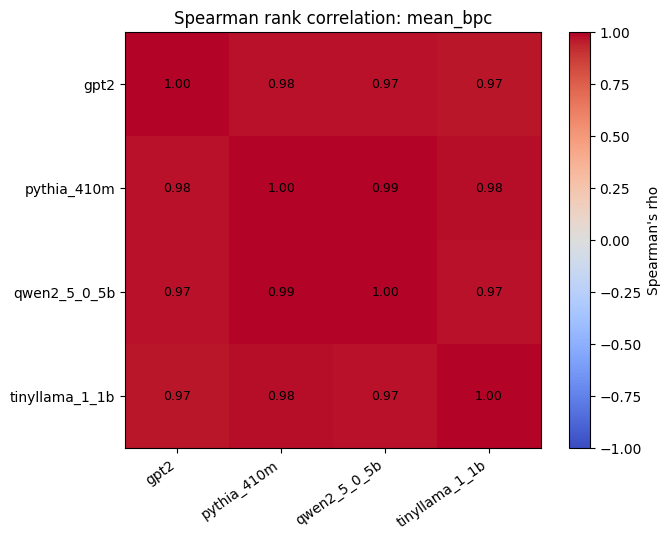

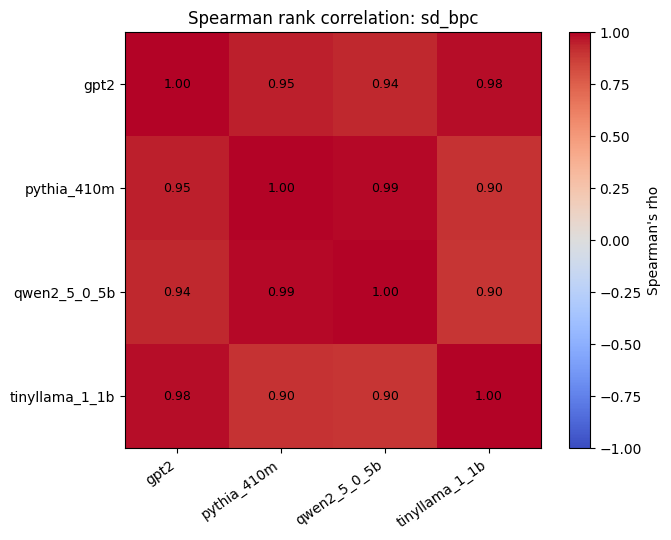

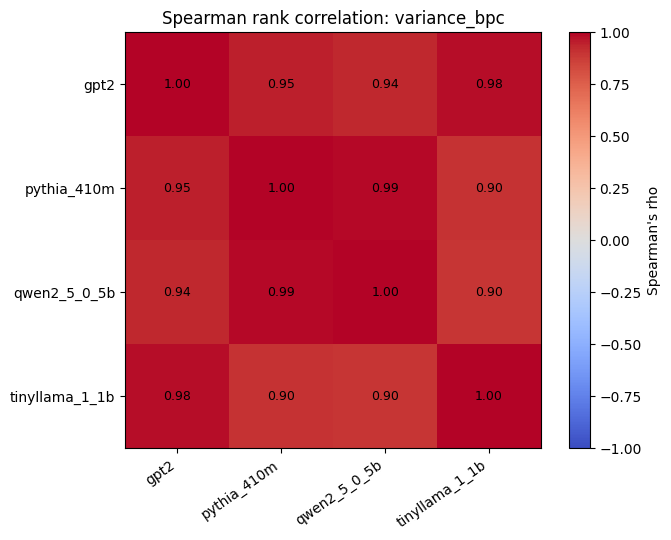

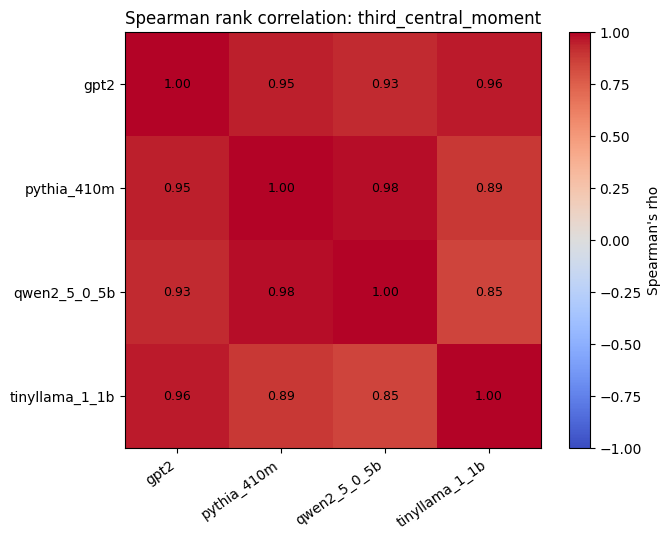

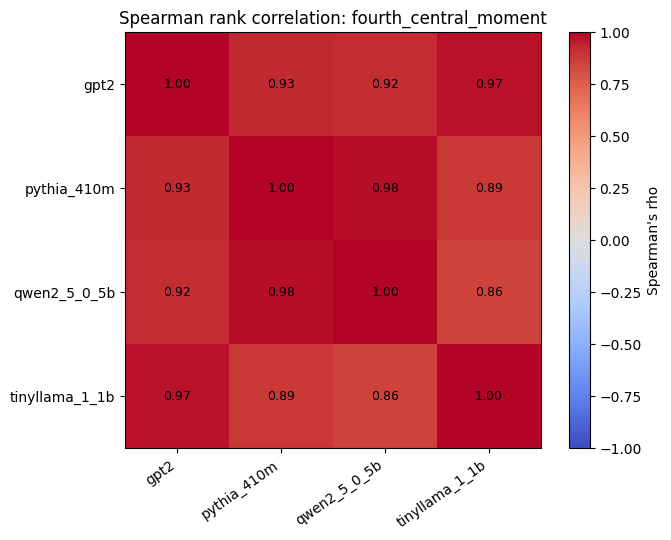

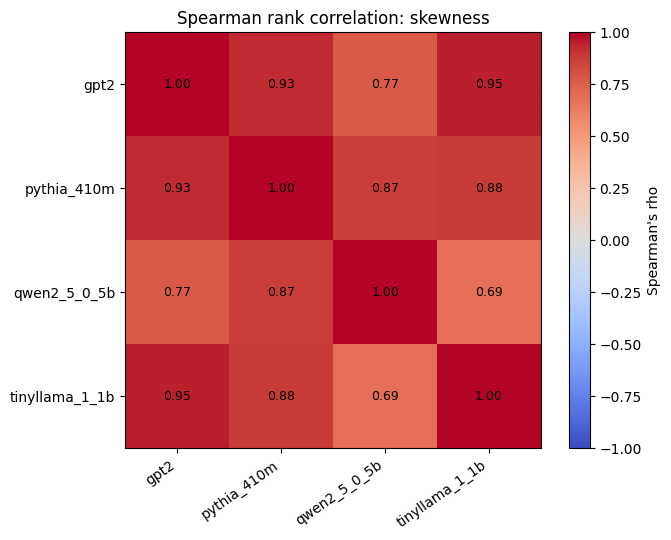

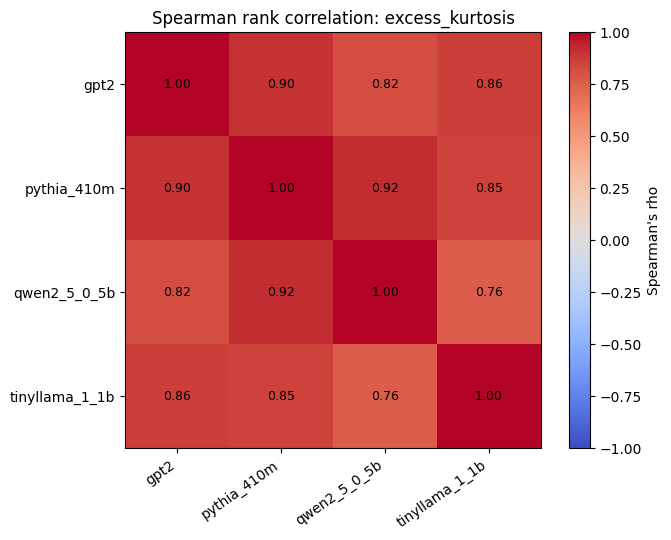

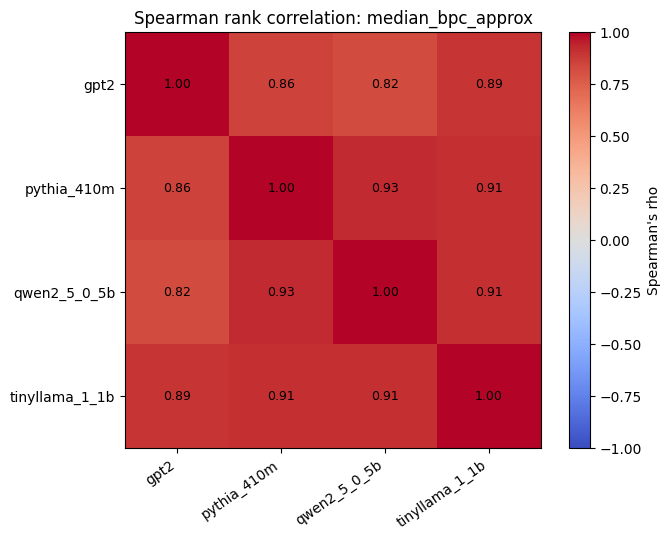

In [15]:
import matplotlib.pyplot as plt

for measure in MEASURES:
    if measure not in spearman_matrices:
        continue
    matrix = spearman_matrices[measure]
    if matrix.empty:
        continue
    fig, ax = plt.subplots(figsize=(7, 5.5))
    im = ax.imshow(matrix.to_numpy(dtype=float), vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(f"Spearman rank correlation: {measure}")
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            value = matrix.iloc[i, j]
            if np.isfinite(value):
                ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)
    fig.colorbar(im, ax=ax, label="Spearman's rho")
    fig.tight_layout()
    fig.savefig(OUTPUT_ROOT / f"spearman_heatmap_{measure}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [16]:
from pathlib import Path
import zipfile
from IPython.display import FileLink, display

figure_dir = Path(OUTPUT_ROOT)
figures = sorted(figure_dir.glob("*.png"))

if not figures:
    raise FileNotFoundError(f"No PNG figures found in {figure_dir}")

zip_path = figure_dir / "cross_model_figures.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for figure in figures:
        zf.write(figure, arcname=figure.name)

print(f"Packaged {len(figures)} figures.")
display(FileLink(str(zip_path)))

Packaged 8 figures.


/kaggle/working/poet_model_robustness/cross_model_figures.zip

## 7. Export a compact workbook

The workbook contains model status, source-level moments, raw chunk scores, binned frequency tables, and pairwise correlation results.

In [17]:
xlsx_path = OUTPUT_ROOT / "cross_model_poet_robustness.xlsx"
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    model_runs_df.to_excel(writer, sheet_name="model_status", index=False)
    source_summary_df.to_excel(writer, sheet_name="source_moments", index=False)
    chunk_scores_df.to_excel(writer, sheet_name="chunk_scores", index=False)
    frequency_df.to_excel(writer, sheet_name="binned_frequencies", index=False)
    spearman_df.to_excel(writer, sheet_name="spearman_pairs", index=False)
    kendall_df.to_excel(writer, sheet_name="kendall_pairs", index=False)

print("All outputs saved to:", OUTPUT_ROOT)
print("Workbook:", xlsx_path)

All outputs saved to: /kaggle/working/poet_model_robustness
Workbook: /kaggle/working/poet_model_robustness/cross_model_poet_robustness.xlsx


In [18]:
from itertools import combinations
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from IPython.display import display

N_BOOTSTRAP = 5000
BOOTSTRAP_SEED = 20261009

rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_rows = []

valid_summary = source_summary_df[
    source_summary_df["status"].eq("SUCCESS")
].copy()

model_order = [
    m for m in MODEL_NAMES
    if m in set(valid_summary["model_key"])
]

for measure in MEASURES:
    wide = valid_summary.pivot_table(
        index="poet",
        columns="model_key",
        values=measure,
        aggfunc="first"
    )

    for model_1, model_2 in combinations(model_order, 2):
        if model_1 not in wide.columns or model_2 not in wide.columns:
            continue

        pair = wide[[model_1, model_2]].apply(
            pd.to_numeric, errors="coerce"
        ).dropna()

        x = pair[model_1].to_numpy(dtype=float)
        y = pair[model_2].to_numpy(dtype=float)
        n = len(pair)

        result = {
            "measure": measure,
            "model_1": model_1,
            "model_2": model_2,
            "n_poets": n,
            "spearman_rho": np.nan,
            "ci_95_lower": np.nan,
            "ci_95_upper": np.nan,
            "valid_bootstrap_replicates": 0,
        }

        if n < 4 or np.unique(x).size < 2 or np.unique(y).size < 2:
            bootstrap_rows.append(result)
            continue

        result["spearman_rho"] = float(spearmanr(x, y).statistic)
        bootstrap_rhos = []

        for _ in range(N_BOOTSTRAP):
            indices = rng.integers(0, n, size=n)
            xb = x[indices]
            yb = y[indices]

            # Skip samples where correlation is undefined.
            if np.unique(xb).size < 2 or np.unique(yb).size < 2:
                continue

            rho = spearmanr(xb, yb).statistic

            if np.isfinite(rho):
                bootstrap_rhos.append(float(rho))

        result["valid_bootstrap_replicates"] = len(bootstrap_rhos)

        if len(bootstrap_rhos) >= 1000:
            result["ci_95_lower"] = float(
                np.quantile(bootstrap_rhos, 0.025)
            )
            result["ci_95_upper"] = float(
                np.quantile(bootstrap_rhos, 0.975)
            )

        bootstrap_rows.append(result)

bootstrap_ci_df = pd.DataFrame(bootstrap_rows)

output_file = OUTPUT_ROOT / "spearman_bootstrap_confidence_intervals.csv"
bootstrap_ci_df.to_csv(output_file, index=False)

display(
    bootstrap_ci_df.sort_values(
        ["measure", "model_1", "model_2"]
    ).reset_index(drop=True)
)

print(f"Results saved to: {output_file}")

,measure,model_1,model_2,n_poets,spearman_rho,ci_95_lower,ci_95_upper,valid_bootstrap_replicates
0,excess_kurtosis,gpt2,pythia_410m,28,0.903120,0.775389,0.958780,5000
1,excess_kurtosis,gpt2,qwen2_5_0_5b,28,0.816092,0.587890,0.925825,5000
2,excess_kurtosis,gpt2,tinyllama_1_1b,28,0.861522,0.645758,0.947838,5000
3,excess_kurtosis,pythia_410m,qwen2_5_0_5b,28,0.915709,0.761928,0.974628,5000
4,excess_kurtosis,pythia_410m,tinyllama_1_1b,28,0.852217,0.640551,0.951101,5000
5,excess_kurtosis,qwen2_5_0_5b,tinyllama_1_1b,28,0.759168,0.458192,0.935131,5000
6,fourth_central_moment,gpt2,pythia_410m,28,0.925014,0.746900,0.992312,5000
7,fourth_central_moment,gpt2,qwen2_5_0_5b,28,0.915709,0.720620,0.992845,5000
8,fourth_central_moment,gpt2,tinyllama_1_1b,28,0.969349,0.899367,0.987363,5000
9,fourth_central_moment,pythia_410m,qwen2_5_0_5b,28,0.981390,0.928918,0.993407,5000


Results saved to: /kaggle/working/poet_model_robustness/spearman_bootstrap_confidence_intervals.csv
